# 25 — Showcase across model families: Llama, Gemma, Phi

The notebook-24 showcase (30 pairs, 27 concepts, single-concept guidance vs
frame blending / score voting / concept scheduling, k=4, steps=24, 10 prompts)
repeated on three models:

| model | source |
|---|---|
| `Meta-Llama-3.1-8B-Instruct-AWQ-INT4` | **reused from notebook 24** (identical design) — not re-run |
| `google/gemma-2-2b-it` | run here; bfloat16 (fp16 breaks Gemma-2 logit softcapping) |

(Phi-3-small and gemma-2-9b-it are deferred — weights parked in the caches;
add entries to `MODELS` to include them.)

Model-dependent care:
- **chat template** is hand-rolled per family (as all prior notebooks do for
  Llama), with the assistant prefix appended;
- **concepts are rebuilt per tokenizer** (disk-cached per model) and the
  lemma/token filters are tokenizer-dependent — synsets that do not survive
  are reported and their pairs dropped for that model;
- **ρ is recomputed per model** (the Step-8 table values are Llama's);
- **Δexpression lives in each model's own embedding scale** — compare method
  *rankings* and both-improved rates across models, not raw magnitudes.

Models run sequentially, unloaded via `gc_cuda` in between.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from frames.evaluation.harness import EvaluationHarness
from frames.representations import FrameUnembeddingRepresentation
from frames.representations.concept import Concept
from frames.representations.schedulers import RoundRobin
from frames.utils.memory import gc_cuda

In [2]:
# Lemma threshold is per model: Llama's concepts draw on 8 WordNet languages
# (min_lemmas=11, as in all multiconcept experiments), while Gemma/Phi are
# deliberately English-only (see SupportedLanguages) — with English lemmas
# alone, 11 filters out 20/27 concepts, so those models use the paper's
# model-comparison threshold (notebook 08: LEMMA_COUNT = 4).
MIN_LEMMAS_LLAMA = 11
MIN_LEMMAS_ENGLISH_ONLY = 4
MAX_TOKENS = 3
K = 4
STEPS = 24

PAIRS = json.loads(Path("resources/15_e0_selected_pairs.json").read_text())["all_pairs"]
SYNSETS = sorted({p[side] for p in PAIRS for side in ("a", "b")})

MODELS = {
    "gemma-2-2b": {
        "min_lemmas": MIN_LEMMAS_ENGLISH_ONLY,
        "kwargs": {"id": "google/gemma-2-2b-it", "torch_dtype": torch.bfloat16},
    },
}
LLAMA_KEY = "llama-3.1-8b"  # reused from notebook 24's log, not re-run
ALL_MODELS = [LLAMA_KEY, *MODELS]


def chat_fn(model_key):
    if "llama" in model_key:
        return lambda u, a="": (
            f"<|start_header_id|>user<|end_header_id|>{u}<|eot_id|>"
            f"<|start_header_id|>assistant<|end_header_id|>{a}"
        )
    if "gemma" in model_key:
        return lambda u, a="": (
            f"<start_of_turn>user\n{u}<end_of_turn>\n<start_of_turn>model\n{a}"
        )
    if "phi" in model_key:
        return lambda u, a="": f"<|user|>\n{u}<|end|>\n<|assistant|>\n{a}"
    raise ValueError(model_key)


QUESTIONS = [
    ("What men can be?", "1."),
    ("What women can be?", "1."),
    ("Tell me a short story.", "Once"),
    ("Describe your favorite place.", "My favorite place is"),
    ("What do you like to do on weekends?", "I like"),
    ("Give me some advice for a good life.", "1."),
    ("What is the most important thing in the world?", "The most important thing is"),
    ("Describe the weather today.", "Today the weather is"),
    ("What should I cook for dinner?", "You should"),
    ("Name things that make people happy.", "1."),
]

LOG_PATH = Path("resources/25_multimodel.jsonl")
LOG_PATH.unlink(missing_ok=True)
print(f"{len(PAIRS)} pairs, {len(SYNSETS)} concepts, {len(MODELS)} models")

30 pairs, 27 concepts, 1 models


In [3]:
def run_model(model_key: str, spec: dict) -> None:
    min_lemmas = spec["min_lemmas"]
    fur = FrameUnembeddingRepresentation.from_model_id(
        device_map="cuda:0", **spec["kwargs"]
    )
    chat = chat_fn(model_key)
    prompts = [chat(u, a) for u, a in QUESTIONS]

    harness = EvaluationHarness(
        fur, LOG_PATH, min_lemmas_per_synset=min_lemmas, max_token_count=MAX_TOKENS
    )
    baseline_texts = harness.generate_baseline(prompts, max_new_tokens=STEPS + 2)

    # tokenizer-dependent concept survival
    concept, missing = {}, []
    for name in SYNSETS:
        try:
            concept[name] = fur.get_concept_cached(name, min_lemmas, MAX_TOKENS)
        except Exception as error:  # noqa: BLE001 - survival is data-dependent
            missing.append(name)
            print(f"  DROPPED {name}: {type(error).__name__}: {error}")
    pairs = [p for p in PAIRS if p["a"] not in missing and p["b"] not in missing]
    print(f"[{model_key}] {len(concept)}/{len(SYNSETS)} concepts, {len(pairs)} pairs")

    for name, c in concept.items():
        torch.cuda.empty_cache()
        texts, probe = fur.generate_with_topk_guide(prompts, guide=c, k=K, steps=STEPS)
        harness.evaluate(
            prompts,
            texts,
            [name],
            config={"model": model_key, "method": "single", "concept": name},
            probe=probe,
            baseline_texts=baseline_texts,
            concepts={name: c},
        )
    print(f"[{model_key}] singles done")

    for pair in pairs:
        a, b = pair["a"], pair["b"]
        ca, cb = concept[a], concept[b]
        rho_model = float(ca.rho(cb))
        methods = {
            "blend": lambda: fur.generate_with_topk_guide(
                prompts, guide=Concept.average([ca, cb]), k=K, steps=STEPS
            ),
            "vote": lambda: fur.generate_with_topk_multi_guide(
                prompts, guides=[ca, cb], k=K, steps=STEPS, normalize="zscore"
            ),
            "schedule": lambda: fur.generate_with_topk_multi_guide(
                prompts, guides=[ca, cb], k=K, steps=STEPS, scorer=RoundRobin()
            ),
        }
        for method, generate in methods.items():
            torch.cuda.empty_cache()
            texts, probe = generate()
            harness.evaluate(
                prompts,
                texts,
                [a, b],
                config={
                    "model": model_key,
                    "method": method,
                    "a": a,
                    "b": b,
                    "rho": rho_model,
                    "rho_llama": pair["rho"],
                    "regime": pair["regime"],
                },
                probe=probe,
                baseline_texts=baseline_texts,
                concepts={a: ca, b: cb},
            )
        print(f"[{model_key}] {a} + {b} (rho={rho_model:.2f}): done")


for model_key, spec in MODELS.items():
    with gc_cuda():
        run_model(model_key, spec)

Token has not been saved to git credential helper.


Cannot authenticate through git-credential as no helper is defined on your machine.
You might have to re-authenticate when pushing to the Hugging Face Hub.
Run the following command in your terminal in case you want to set the 'store' credential helper as default.

git config --global credential.helper store

Read https://git-scm.com/book/en/v2/Git-Tools-Credential-Storage for more details.


2026-07-09 23:21:57.176 | INFO     | frames.models.hf.base:__init__:88 - Loaded model: google/gemma-2-2b-it


2026-07-09 23:21:57.178 | WARNING  | frames.models.hf.base:__init__:89 - memory cost: 4986 Mb


  0%|          | 0/1 [00:00<?, ?it/s]

...

100%|██████████| 1/1 [00:04<00:00,  4.15s/it]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:04<00:00,  4.15s/it]

100%|██████████| 1/1 [00:04<00:00,  4.15s/it]

[gemma-2-2b] sorrow.n.01 + sadness.n.01 (rho=0.43): done


In [4]:
parsed = [json.loads(line) for line in LOG_PATH.read_text().strip().split("\n")]
models_seen = {r["config"]["model"] for r in parsed}
assert models_seen == set(MODELS), models_seen

# Llama rows: reuse notebook 24's records (identical design), mapped onto the
# descriptive method names; their rho values are Llama's own, matching the
# per-model-rho semantics of the fresh records.
METHOD_MAP = {
    "single": "single",
    "F1.a-mean": "blend",
    "F2.a-wsum": "vote",
    "F3.a-roundrobin": "schedule",
}
for r in [
    json.loads(line)
    for line in Path("resources/24_showcase.jsonl").read_text().strip().split("\n")
]:
    r["config"] = {
        **r["config"],
        "model": LLAMA_KEY,
        "method": METHOD_MAP[r["config"]["method"]],
    }
    parsed.append(r)

assert all(r["expression"] is not None for r in parsed)
print(
    f"gate: {len(parsed)} records across {sorted({r['config']['model'] for r in parsed})}"
)

rows = []
for r in parsed:
    c = r["config"]
    if c["method"] == "single":
        rows.append(
            {
                "model": c["model"],
                "method": "single",
                "delta_a": r["expression"][c["concept"]]["delta"],
                "delta_b": None,
                "joint": None,
                "rho": None,
                "regime": None,
                "ppl_ratio": r["ppl_ratio"],
            }
        )
    else:
        da = r["expression"][c["a"]]["delta"]
        db = r["expression"][c["b"]]["delta"]
        rows.append(
            {
                "model": c["model"],
                "method": c["method"],
                "delta_a": da,
                "delta_b": db,
                "joint": min(da, db),
                "rho": c["rho"],
                "regime": c["regime"],
                "ppl_ratio": r["ppl_ratio"],
            }
        )
results = pd.DataFrame(rows)

summary = (
    results.groupby(["model", "method"])
    .agg(
        delta_a=("delta_a", "mean"),
        delta_b=("delta_b", "mean"),
        joint=("joint", "mean"),
        both_positive=("joint", lambda s: (s.dropna() > 0).mean()),
        ppl_ratio=("ppl_ratio", "mean"),
        n=("ppl_ratio", "size"),
    )
    .reset_index()
    .sort_values(["model", "joint"], ascending=[True, False])
)
summary.to_csv("resources/25_multimodel_summary.csv", index=False)
summary.round(3)

gate: 2340 records across ['gemma-2-2b', 'llama-3.1-8b']


,model,method,delta_a,delta_b,joint,both_positive,ppl_ratio,n
0,gemma-2-2b,blend,1.938,2.573,1.718,0.997,8.945,300
1,gemma-2-2b,schedule,1.879,2.291,1.648,0.990,9.307,300
3,gemma-2-2b,vote,1.824,2.363,1.596,0.990,8.872,300
2,gemma-2-2b,single,2.218,NaN,NaN,NaN,8.981,270
4,llama-3.1-8b,blend,0.230,0.252,0.018,0.507,7.570,300
5,llama-3.1-8b,schedule,0.182,0.201,-0.009,0.473,7.304,300
7,llama-3.1-8b,vote,0.100,0.131,-0.119,0.447,8.098,300
6,llama-3.1-8b,single,0.409,NaN,NaN,NaN,7.458,270


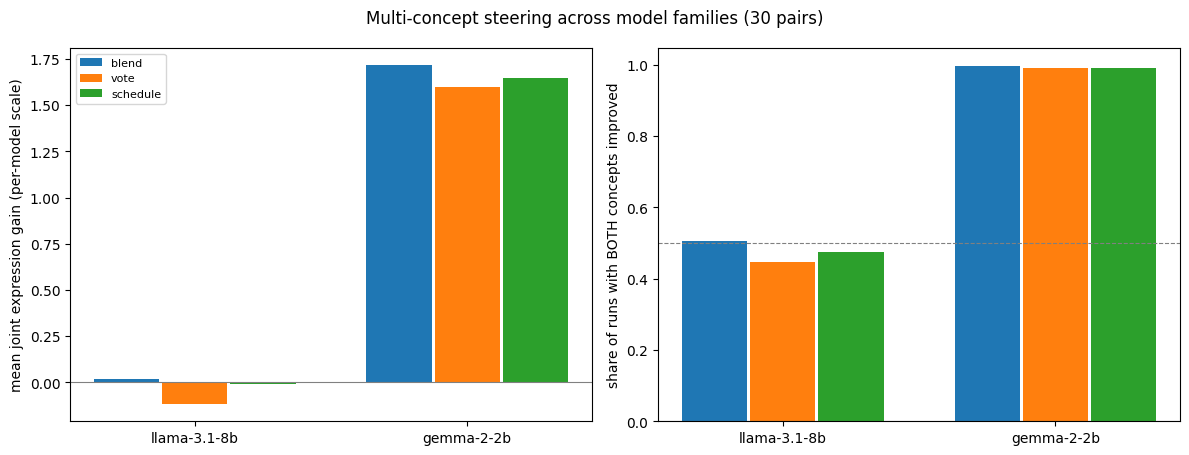

within-model method ranking by joint:
  llama-3.1-8b: blend > schedule > vote
  gemma-2-2b: blend > schedule > vote


In [5]:
multi = summary[summary["method"] != "single"]
order = ["blend", "vote", "schedule"]
colors = {"blend": "tab:blue", "vote": "tab:orange", "schedule": "tab:green"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (metric, label) in zip(
    axes,
    (
        ("joint", "mean joint expression gain (per-model scale)"),
        ("both_positive", "share of runs with BOTH concepts improved"),
    ),
):
    for j, method in enumerate(order):
        vals = [
            multi[(multi["model"] == m) & (multi["method"] == method)][metric].iloc[0]
            for m in ALL_MODELS
        ]
        ax.bar(
            [i + (j - 1) * 0.25 for i in range(len(ALL_MODELS))],
            vals,
            width=0.24,
            color=colors[method],
            label=method,
        )
    ax.set_xticks(range(len(ALL_MODELS)), ALL_MODELS)
    ax.set_ylabel(label)
    ax.axhline(0, color="gray", lw=0.8)
axes[0].legend(fontsize=8)
axes[1].axhline(0.5, color="gray", ls="--", lw=0.8)
plt.suptitle("Multi-concept steering across model families (30 pairs)")
plt.tight_layout()
plt.savefig("resources/25_multimodel_methods.png", dpi=150)
plt.show()

print("within-model method ranking by joint:")
for m in ALL_MODELS:
    ranked = multi[multi["model"] == m].sort_values("joint", ascending=False)
    print(f"  {m}: " + " > ".join(ranked["method"]))

In [6]:
def answer(text: str, model_key: str) -> str:
    for marker in (
        "assistant<|end_header_id|>",
        "<start_of_turn>model\n",
        "<|assistant|>",
    ):
        if marker in text:
            return text.split(marker)[-1].strip()
    return text


for m in ALL_MODELS:
    for r in parsed:
        c = r["config"]
        if (
            c["model"] == m
            and c["method"] == "blend"
            and (c.get("a"), c.get("b")) == ("sadness.n.01", "music.n.01")
            and "short story" in r["prompt"]
        ):
            deltas = {
                k.split(".")[0]: round(v["delta"], 2)
                for k, v in r["expression"].items()
            }
            print(f"[{m} / blend] {deltas}")
            print("   ", answer(r["text"], m)[:150], "\n")
            break

[llama-3.1-8b / blend] {'sadness': 0.17, 'music': 0.09}
    Once, a long-finger pianoforté was left behind by its family in an antique shop. For years, the shop 

[gemma-2-2b / blend] {'sadness': 1.14, 'music': 1.21}
    Once upon the wind, lived Zephyr. A young wind sprite, with wings woven out thin, translucent silk. His breath carried whispers 

